# Notebook to Learn about how to use Tensors


Based on this video: https://www.youtube.com/watch?v=2yBEZzQu8dA

Tensor documentation!
https://docs.pytorch.org/docs/stable/tensors.html

In [1]:
import torch
import numpy as np

### Let's first make a list

In [2]:
#This is a normal python list
list = [1,2,3,4,5]
# And a python array
multi_dimensional_array = [[1,2,3,4,5] , [6,7,8,9,10]]

print(list)
multi_dimensional_array

[1, 2, 3, 4, 5]


[[1, 2, 3, 4, 5], [6, 7, 8, 9, 10]]

### Now compare it to numpy arrays

In [3]:
np1 = np.random.rand(3,4)
np1

array([[0.33989072, 0.55131824, 0.89706526, 0.53924249],
       [0.43647904, 0.92404088, 0.06542839, 0.47034984],
       [0.09907904, 0.10939238, 0.82584569, 0.78420824]])

In [4]:
# Important! numpy arrays are of type float64!
np1.dtype

dtype('float64')

### So, What is a Tensor?

In [5]:
tensor_2d = torch.rand(3,4)
# creating a randomly filled 2d tensor, 3 rows 4 columns
# If only 2 parameters are given, the dimensions parameter is ommited and assumed to be 1
tensor_2d


tensor([[0.5770, 0.5226, 0.9217, 0.0397],
        [0.7691, 0.9843, 0.6594, 0.1150],
        [0.8508, 0.8143, 0.5253, 0.8617]])

A tensor is very similar to a numpy array but it can do more stuff, it is more powerfull. But...

In [6]:
tensor_2d.dtype

torch.float32

Watch out! The data type of tensors in torch is float 32, this can cause some problems when comparing the data.

In [7]:
tensor_3d = torch.zeros(2,3,4)
tensor_3d

tensor([[[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]],

        [[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]]])

A vector is a 1 dimensional tensor and a Matrix a 2d tensor. The first parameter when creating a tensor is the number of dimensions, the second one corresponds to the rows and the third to the columns.

The number of dimensions can also be seen as the number of arrays that are stacked on top of each other.

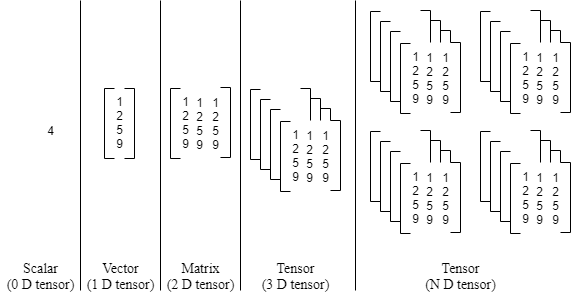

### Example with the an RGB image!!!

In [8]:
# RGB image: 224 height × 224 width × 3 channels
image = torch.rand(3, 224, 224)  # PyTorch format: (channels, height, width)
print(f"Image shape: {image.shape}")

# dimension 0 (3): Channel (Red, Green, Blue)
# dimension 1 (224): Height (rows of pixels)
# dimension 2 (224): Width (columns of pixels)


Image shape: torch.Size([3, 224, 224])


In [9]:
# Access red channel
red_channel = image[0, :, :]  # All rows, all columns, channel 0
print(f"Red channel shape: {red_channel.shape}")  # (224, 224)

Red channel shape: torch.Size([224, 224])


**Visual:**
```
Channel 0 (Red):       Channel 1 (Green):     Channel 2 (Blue):
[R R R R R ...]        [G G G G G ...]        [B B B B B ...]
[R R R R R ...]        [G G G G G ...]        [B B B B B ...]
[R R R R R ...]        [G G G G G ...]        [B B B B B ...]
...                    ...                     ...

224 rows
224 columns per row
3 channels (stacked)

Video Frame Example

In [10]:
# 10 frames of video, each 480×640 grayscale
video = torch.rand(10, 480, 640)

# dimension 0 (10): Frame number (time)
# dimension 1 (480): Height
# dimension 2 (640): Width

### 4D Tensor - Common in Deep Learning (4 dimensions)

In [11]:
# Batch of images
batch = torch.rand(32, 3, 224, 224)
print(f"Batch shape: {batch.shape}")  # torch.Size([32, 3, 224, 224])
print(f"Number of dimensions: {batch.ndim}")  # 4

# dimension 0 (32): Batch size (how many images)
# dimension 1 (3): Channels (RGB)
# dimension 2 (224): Height
# dimension 3 (224): Width

Batch shape: torch.Size([32, 3, 224, 224])
Number of dimensions: 4


```

**What each dimension means:**
- **Dimension 0 (batch)**: Which image in the batch
- **Dimension 1 (channels)**: Which color channel
- **Dimension 2 (height)**: Which row of pixels
- **Dimension 3 (width)**: Which column of pixels

**Visual breakdown:**
```
Batch dimension (32 images):
┌─────────────────┐
│ Image 0:        │
│  [3, 224, 224]  │ ← 3 channels, 224×224 pixels
├─────────────────┤
│ Image 1:        │
│  [3, 224, 224]  │
├─────────────────┤
│ ...             │
├─────────────────┤
│ Image 31:       │
│  [3, 224, 224]  │
└─────────────────┘

Each image has 3 channels:
Red:              Green:            Blue:
[224×224 pixels]  [224×224 pixels]  [224×224 pixels]

So if there are conflicts because of datatype difference howcan you convert one to the other?

In [12]:
# Create tensor for numpy array =>
converted_tensor = torch.tensor(np1) 

# Just pass the array to torch.tensor()
converted_tensor

tensor([[0.3399, 0.5513, 0.8971, 0.5392],
        [0.4365, 0.9240, 0.0654, 0.4703],
        [0.0991, 0.1094, 0.8258, 0.7842]], dtype=torch.float64)

Important to note that the datatype is float64 (still the default for numpy arrays) and that it is now defined as a tensor, written before the tensor itself!

So how can you change the datatype to the tensor default? (float32)

In [13]:
# se puede usar .float() para cambiar el type de float64 a float32
# Para hacer el cambio inverso se utiliza .double() (Ya que float64 son el doble de bits que float32)
tensor_float32 = converted_tensor.float()
print(tensor_float32)
tensor_float32.dtype

tensor([[0.3399, 0.5513, 0.8971, 0.5392],
        [0.4365, 0.9240, 0.0654, 0.4703],
        [0.0991, 0.1094, 0.8258, 0.7842]])


torch.float32

In [14]:
# Create a tensor
x = torch.tensor([1.0, 2.0, 3.0])
print(f"Original dtype: {x.dtype}")

# Method 1: Using .to()
x_int = x.to(torch.int32)
print(x_int.dtype)

# Method 2: Using specific conversion methods
x_long = x.long()      # int64
x_float = x.float()    # float32
x_double = x.double()  # float64
x_bool = x.bool()      # boolean


print(x_long.dtype)
print(x_float.dtype)
print(x_double.dtype)
print(x_bool.dtype)
# Note: Operations between tensors require matching dtypes!

Original dtype: torch.float32
torch.int32
torch.int64
torch.float32
torch.float64
torch.bool


A su vez se puede usar.half() para devolver un tensor de tipo float16

zeros_tensor = torch.zeros(2,3)

### Some of the most important Functionsare the following: 

In [15]:

zeros_tensor = torch.zeros(2,3,3)
ones_tensor = torch.ones(2,3,3)
full_tensor = torch.full((2,3,3) ,7.0)

print(zeros_tensor)
print(ones_tensor)
full_tensor

tensor([[[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]]])
tensor([[[1., 1., 1.],
         [1., 1., 1.],
         [1., 1., 1.]],

        [[1., 1., 1.],
         [1., 1., 1.],
         [1., 1., 1.]]])


tensor([[[7., 7., 7.],
         [7., 7., 7.],
         [7., 7., 7.]],

        [[7., 7., 7.],
         [7., 7., 7.],
         [7., 7., 7.]]])

In [16]:
eye = torch.eye(3)
eye # Eye creates an identity matrix  

tensor([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.]])

In [17]:
random = torch.rand(2,3)
random # Initialises a tensor with random values [0,1)

tensor([[0.6338, 0.8374, 0.2887],
        [0.0189, 0.3558, 0.2371]])

In [18]:
random_normal = torch.randn(2,3)
random_normal # normal  distribution

tensor([[ 1.9641,  0.5219,  0.5249],
        [ 1.8299, -0.2826, -0.0052]])

### The "_like" functions match the shape of the reference tensor

In [19]:
reference = torch.tensor([[1, 2], [3, 4]])
reference

tensor([[1, 2],
        [3, 4]])

In [20]:
zl = torch.zeros_like(reference)
ol = torch.ones_like(reference)
rl = torch.rand_like(reference.float())
print(zl, ol, rl, sep="\n\n")

tensor([[0, 0],
        [0, 0]])

tensor([[1, 1],
        [1, 1]])

tensor([[0.4177, 0.7905],
        [0.4661, 0.1095]])


Do you have a gpu?

In [21]:
# Check CUDA availability
print(f"CUDA available: {torch.cuda.is_available()}")

# Checks if your system gas an NVIDIA GPU installed and the CUDA drivers properly installed.

CUDA available: True


In [22]:
# This counts how many GPUs are available 
print(f"CUDA device count: {torch.cuda.device_count()}")

CUDA device count: 1


### What is CUDA?
CUDA (Compute Unified Device Architecture) is NVIDIA's parallel computing platform and programming model. It allows you to use NVIDIA GPUs (Graphics Processing Units) for general-purpose computing, not just graphics.

GPUs are much faster than CPUs 

In [23]:
# Create a device object that represents where the tensors will live. The calculations will happen there!
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [24]:
# Create tensor on CPU
# It is important to note! IF NO DEVICE IS SPECIFIED IT DEFAULTS TO CPU!
x_cpu = torch.ones(3, 3)
print(f"Tensor on: {x_cpu.device}")

Tensor on: cpu


There are two ways of dealing with this. Creating a tensor already in the device or creating it, and then moving it to the device

In [25]:
# Create tensor directly on device
x_direct = torch.ones(3, 3, device=device)
x_direct.device

device(type='cuda', index=0)

In [26]:
# Move tensor to device
x_device = x_cpu.to(device)
print(f"Tensor on: {x_device.device}")


Tensor on: cuda:0


In [27]:
# CRITICAL: All tensors in an operation MUST be on same device!
# result = x_cpu + x_device  # ERROR if on different devices!

# Move back to CPU
x_back = x_device.cpu()


# .cpu() is shorthand for .to('cpu')
# .cuda() is shorthand for .to('cuda')

x_cuda = x_back.cuda()

#### Main points:

1. GPU is faster, use it if available
2. Default device is CPU 
3. Always move all tensors to the same device before operations

Common workflow:

In [28]:
#device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#model = MyModel().to(device)
#data = data.to(device)
#output = model(data)  # All on same device

Now for other important manipulations!

#### Shape manipulation

In [29]:
t = torch.arange(12)
print(t)

t_reshaped =t.reshape(3,4) 
t_reshaped # To reshape the tensor to a desired form

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])


tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])

In [30]:
viewed = t.view(2,6)
viewed

tensor([[ 0,  1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10, 11]])

In [31]:
# Create original tensor
t = torch.tensor([1, 2, 3, 4])
print(f"Original: {t}")
print(f"Original memory address: {t.data_ptr()}")

# Create a view (shares memory)
t_view = t.view(2, 2)
print(f"\nView: {t_view}")
print(f"View memory address: {t_view.data_ptr()}")  # SAME address!
## This means that the tensor is overwitten, and it saves memory, as they share the same memory (address)

# Modify the view
t_view[0, 0] = 999

# Original is also changed!
print(f"\nAfter modifying view:")
print(f"View: {t_view}")
print(f"Original: {t}")  # Also changed to [999, 2, 3, 4]!

Original: tensor([1, 2, 3, 4])
Original memory address: 94789269002432

View: tensor([[1, 2],
        [3, 4]])
View memory address: 94789269002432

After modifying view:
View: tensor([[999,   2],
        [  3,   4]])
Original: tensor([999,   2,   3,   4])


In [32]:
example_tensor1 = torch.ones(2, 3, 1, 4)
squeezed = example_tensor1.squeeze()  # Only removes dim 2
print(example_tensor1, squeezed, sep='\n')
print(f"Shape: {squeezed.shape}\n")  # torch.Size([2, 3, 4])

example_tensor = torch.tensor([1, 2, 3, 4])
print(example_tensor)
print(f"Original shape: {example_tensor.shape}\n")  # torch.Size([4])

# Add dimension at position 0
unsqueezed_0 = t.unsqueeze(0)
print(f"Unsqueezed at 0: {unsqueezed_0.shape}")  # torch.Size([1, 4])
print(f"Tensor: {unsqueezed_0}")  # tensor([[1, 2, 3, 4]])


tensor([[[[1., 1., 1., 1.]],

         [[1., 1., 1., 1.]],

         [[1., 1., 1., 1.]]],


        [[[1., 1., 1., 1.]],

         [[1., 1., 1., 1.]],

         [[1., 1., 1., 1.]]]])
tensor([[[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]],

        [[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]]])
Shape: torch.Size([2, 3, 4])

tensor([1, 2, 3, 4])
Original shape: torch.Size([4])

Unsqueezed at 0: torch.Size([1, 4])
Tensor: tensor([[999,   2,   3,   4]])


In [33]:
t = torch.tensor([1, 2, 3, 4])
print(f"Original shape: {t.shape}") 

# Add dimension at position 0
unsqueezed_0 = t.unsqueeze(0)
print(f"Unsqueezed at 0: {unsqueezed_0.shape}")  # torch.Size([1, 4])
print(f"Tensor: {unsqueezed_0}")  # tensor([[1, 2, 3, 4]])



# Add dimension at position 1
unsqueezed_1 = t.unsqueeze(1)
print(f"Unsqueezed at 1: {unsqueezed_1.shape}")  # torch.Size([4, 1])
print(f"Tensor:\n{unsqueezed_1}")
# tensor([[1],
#         [2],
#         [3],
#         [4]])

 

Original shape: torch.Size([4])
Unsqueezed at 0: torch.Size([1, 4])
Tensor: tensor([[1, 2, 3, 4]])
Unsqueezed at 1: torch.Size([4, 1])
Tensor:
tensor([[1],
        [2],
        [3],
        [4]])


#### Flatten

In [34]:
t = torch.tensor([[[1, 2], [3, 4]], 
                  [[5, 6], [7, 8]]])
print(f"Original shape: {t.shape}")  # torch.Size([2, 2, 2])
print(f"Original:\n{t}")

# Flatten everything to 1D
flattened = t.flatten()
print(f"\nFlattened shape: {flattened.shape}")  # torch.Size([8])
print(f"Flattened: {flattened}")  # tensor([1, 2, 3, 4, 5, 6, 7, 8])

# Flatten from specific dimension
flat_from_1 = t.flatten(start_dim=1)  # Keep dim 0, flatten rest
print(f"\nFlatten from dim 1: {flat_from_1.shape}")  # torch.Size([2, 4])
print(f"Result:\n{flat_from_1}")
# tensor([[1, 2, 3, 4],
#         [5, 6, 7, 8]])

# May or may not share memory (implementation detail)
# Typically returns a contiguous copy

Original shape: torch.Size([2, 2, 2])
Original:
tensor([[[1, 2],
         [3, 4]],

        [[5, 6],
         [7, 8]]])

Flattened shape: torch.Size([8])
Flattened: tensor([1, 2, 3, 4, 5, 6, 7, 8])

Flatten from dim 1: torch.Size([2, 4])
Result:
tensor([[1, 2, 3, 4],
        [5, 6, 7, 8]])


## Example operations accross dimensions

In [35]:
# Start with a batch of images
batch = torch.rand(32, 3, 224, 224)
print(f"Original shape: {batch.shape}")
# (32 images, 3 channels, 224 height, 224 width)

# Operation along different dimensions:

# 1. Mean across batch dimension (dim=0)
mean_image = batch.mean(dim=0)
print(f"Mean across batch: {mean_image.shape}")  # (3, 224, 224)
# Result: Average image from all 32 images

# 2. Mean across channel dimension (dim=1)
grayscale = batch.mean(dim=1)
print(f"Mean across channels: {grayscale.shape}")  # (32, 224, 224)
# Result: Convert RGB to grayscale (32 images)

# 3. Mean across height dimension (dim=2)
height_avg = batch.mean(dim=2)
print(f"Mean across height: {height_avg.shape}")  # (32, 3, 224)
# Result: Average each column of pixels

# 4. Mean across width dimension (dim=3)
width_avg = batch.mean(dim=3)
print(f"Mean across width: {width_avg.shape}")  # (32, 3, 224)
# Result: Average each row of pixels

# 5. Mean across multiple dimensions
per_image_avg = batch.mean(dim=[1, 2, 3])
print(f"Mean per image: {per_image_avg.shape}")  # (32,)
# Result: Single average value for each image

Original shape: torch.Size([32, 3, 224, 224])
Mean across batch: torch.Size([3, 224, 224])
Mean across channels: torch.Size([32, 224, 224])
Mean across height: torch.Size([32, 3, 224])
Mean across width: torch.Size([32, 3, 224])
Mean per image: torch.Size([32])


And in terms of nested loops...

In [36]:
# Shape: (batch=2, channels=3, height=4, width=5)
# This represents 2 images, each with 3 color channels (RGB), 4 pixels tall, 5 pixels wide
tensor = torch.arange(2 * 3 * 4 * 5).reshape(2, 3, 4, 5).float()

In [37]:
for batch_idx in range(tensor.shape[0]):  # dimension 0 (batch)
    for channel_idx in range(tensor.shape[1]):  # dimension 1 (channels)
        for height_idx in range(tensor.shape[2]):  # dimension 2 (height)
            for width_idx in range(tensor.shape[3]):  # dimension 3 (width)
                value = tensor[batch_idx, channel_idx, height_idx, width_idx]
                
                # Only print first few to avoid clutter
                if batch_idx == 0 and channel_idx == 0 and height_idx == 0 and width_idx < 3:
                    print(f"tensor[{batch_idx}, {channel_idx}, {height_idx}, {width_idx}] = {value:.0f}")

print(f"\n... (120 total elements)")

tensor[0, 0, 0, 0] = 0
tensor[0, 0, 0, 1] = 1
tensor[0, 0, 0, 2] = 2

... (120 total elements)


In [38]:
a = torch.tensor([[1, 2], [3, 4]])
b = torch.tensor([[5, 6], [7, 8]])

cat_dim0 = torch.cat([a, b], dim=0)  # vertical
cat_dim1 = torch.cat([a, b], dim=1)  # horizontal
stacked = torch.stack([a, b], dim=0)  # creates new dimension

print(cat_dim0, cat_dim1, stacked, sep='\n')

tensor([[1, 2],
        [3, 4],
        [5, 6],
        [7, 8]])
tensor([[1, 2, 5, 6],
        [3, 4, 7, 8]])
tensor([[[1, 2],
         [3, 4]],

        [[5, 6],
         [7, 8]]])


### So what about masks?

Masks are boolean tensors (True/False) used to filter or modify data
They enable vectorized conditional operations without loops

Like an if statement that iterates through the whole tensor, returning a true or false. 

In [39]:
data = torch.tensor([1, 2, 3, 4, 5, 6])

# Create mask with comparison
mask = data > 3  # tensor([False, False, False, True, True, True])

# Use 1: Filter data (returns only True elements)
filtered = data[mask]  # tensor([4, 5, 6])

print(f"Tensor: {data}\n\nMasked tensor: {filtered}")

Tensor: tensor([1, 2, 3, 4, 5, 6])

Masked tensor: tensor([4, 5, 6])


Example coding the Hubber Loss

In [44]:
class HuberLoss(torch.nn.Module):
    """
    This class implements the HuberLoss from PyTorch. It uses the 
    'mean' reduction function.
    """
    
    # Define attributes
    delta: float
    
    def __init__(self, delta: float = 1.0) -> None:
        """
        This method is the constructor of the class.

        Args:
            delta: Delta parameter. Defaults to 1.0.

        Returns:
            None.
        """
        
        # Call super class constructor
        super().__init__()

        # Set attributes
        self.delta = delta

        return None

    def forward(self, x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        """
        This method is the forward pass of the layer.

        Args:
            x: Predictions tensor. Dimensions: [*].
            y: Targets tensor. Dimensions: [*] (same as x tensor). 

        Returns:
            Outputs tensor. Use the mean reduction function. 
                Dimensions: [].
        """

        # TODO
        outputs = torch.zeros_like(x)
        mask = torch.abs(x-y)<self.delta
        outputs[mask]=0.5*(x[mask]-y[mask])**2
        outputs[~mask]=self.delta*(abs(x[~mask]-y[~mask])-0.5*self.delta)

        
        return torch.mean(outputs)
            

In [45]:
outputs = torch.zeros_like(x)  # Shape: e.g., (100,)
mask = torch.abs(x-y) < self.delta  # Shape: (100,) with True/False

# What happens on each side:
outputs[mask]  # Shape: e.g., (60,) - only True positions
x[mask]        # Shape: (60,) - only True positions
y[mask]        # Shape: (60,) - only True positions

# ❌ WRONG: This creates a shape mismatch!
outputs[mask] = 0.5 * (x - y)**2  
# Left side: (60,)  ← trying to assign from → Right side: (100,)
# ERROR! Can't fit 100 values into 60 positions!

NameError: name 'y' is not defined

In PyTorch, the operators @ and * both perform multiplication, but they work in completely different ways. The @ operator always performs matrix multiplication, following linear algebra rules: rows multiply by columns, and shapes must match accordingly. In contrast, * performs element-wise multiplication, meaning each element multiplies the element in the same position. Because these operations are fundamentally different, they almost never produce the same result unless by coincidence. Understanding this distinction is essential when building neural networks, applying linear layers, or working with tensor math — using the wrong operator can silently produce incorrect results without raising errors.

1. @ → Matrix multiplication (linear algebra)

Combines rows of the left matrix with columns of the right matrix

Requires inner dimensions to match:
(m × n) @ (n × p) → (m × p)

Is used for:

neural network linear layers

projections

dot products

transformations

In [53]:
A = torch.tensor([[1., 2.],
                  [3., 4.]])

B = torch.tensor([[5., 6.],
                  [7., 8.]])

print(A @ B)


tensor([[19., 22.],
        [43., 50.]])


2. * → Element-wise multiplication (Hadamard product)

Multiplies each element with the element at the same position

Requires same shape, or broadcasts

Is used for:

scaling

masking

feature-wise multiplication

In [52]:
print(A * B)


tensor([[ 5., 12.],
        [21., 32.]])


In [54]:
# Two small matrices
A = torch.tensor([[1., 2.],
                  [3., 4.]])

B = torch.tensor([[5., 6.],
                  [7., 8.]])

C = A @ B   # same as torch.matmul(A, B)

print("A @ B =\n", C)


A @ B =
 tensor([[19., 22.],
        [43., 50.]])


In [55]:
A = torch.tensor([[2., 1.],
                  [0., 3.]])

v = torch.tensor([4., 5.])  # vector (2,)

result = A @ v
print(result)

tensor([13., 15.])


In [48]:

# Batch of 3 matrices (3x2x2)
A = torch.randn(3, 2, 2)
B = torch.randn(3, 2, 2)

C = A @ B  # shape: (3, 2, 2)

print(C.shape)

torch.Size([3, 2, 2])


In [49]:
batch = torch.randn(10, 4, 4)   # 10 matrices of shape 4×4
transform = torch.eye(4)        # 4×4 identity

out = batch @ transform

print(out.shape)

torch.Size([10, 4, 4])


In [50]:
x = torch.randn(5, 3)        # batch of 5 vectors, each of dimension 3
W = torch.randn(3, 4)        # weight matrix
b = torch.randn(4)           # bias vector

y = x @ W + b                # linear layer output
print(y.shape)               # (5, 4)

torch.Size([5, 4])
